# 4 · Modeling — Binôme C: CNN baseline and U-Nets

**CRISP-DM phase 4 (Modeling).** Team: Hejer (CNN baseline) & Walid (U-Net) (FR, Binôme C). Previous: [`../3_Data_Preparation.ipynb`](../3_Data_Preparation.ipynb) · Next: [`../5_Evaluation.ipynb`](../5_Evaluation.ipynb)

Supervised binary segmentation, three models in increasing order of capacity:

| Part | Model | Author | Saved as |
|---|---|---|---|
| 1 | **CNN baseline**: encoder–decoder without skip connections | Hejer | `models/C_cnn/` |
| 2 | **U-Net from scratch**: the same idea with skip connections | Walid | `models/C_unet/` |
| 3 | **U-Net with an ImageNet ResNet50 encoder**, focal + Tversky loss, flip test-time augmentation | Walid | `models/C_unet_resnet50/` |

**Provenance.** Hejer and Walid built these models in PyTorch (`archive/C_cnn_original_run_hejer.ipynb`, `archive/C_unet_original_run_walid.ipynb`). Their runs used their own split, which differs from the group's frozen split:
- 40/10/10 by category, not group-aware;
- 288×512 resolution;
- pooled metrics.

This notebook ports their architectures and training recipes to Keras and retrains them **on the shared split, at 352×640, with the shared metrics and threshold rule**, so that C can be compared with A and B. Their original numbers (validation IoU 0.27 CNN, 0.39 U-Net, 0.815 U-Net ResNet34) are **not comparable** with the numbers below:
- their split can put near-duplicate frames of one scene in both train and validation, which inflates validation scores;
- Walid's best encoder was ResNet34, which Keras does not provide (ResNet50 is used here).

**Protocol.** Checkpoints are chosen on the validation IoU (their rule) and thresholds by the shared rule (best per-image mean F1 on validation, blobs under `MIN_OBJECT_PX` removed), as for A and B. The test split is not loaded here; the single test evaluation is in notebook 5 and the explanations (Grad-CAM++ and exact SHAP) in notebook 6.

## TL;DR — from a thumbnail sketch to borrowed eyes

Three supervised models, each adding one idea to the previous one, all trained on the same 42 photographs and judged by the same rules:

| Model | The idea, in one sentence | Trained weights | Validation AuPRC | False-alarm blobs |
|---|---|---|---|---|
| **CNN baseline** (Hejer) | Shrink the photo to 1/8, then redraw the mask from that thumbnail | 0.19 M | 0.411 | 132 of 199 |
| **U-Net** (Walid) | Same, but **skip connections** pass the full-detail notes of the encoder to the decoder, so outlines need not be guessed | 1.9 M | 0.453 | 33 of 47 |
| **U-Net + ImageNet ResNet50** (Walid) | Same U-Net, with an encoder that already learned to see on 1.2 M ImageNet photographs, plus a loss that punishes missed pixels more than false alarms | 30.4 M | **0.728** | 36 of 80 |

(A blind guess scores AuPRC 0.091.)

- **Skip connections help** where the theory says: the U-Net raises AuPRC and cuts the false-alarm blobs from 132 to 33.
- **Borrowed eyes help most:** the pretrained encoder adds about **0.28 AuPRC**. 42 photographs are too few to learn to see from scratch.
- **The price:** the pretrained U-Net finds only 2 of the 12 small validation obstacles.
- **Their original PyTorch numbers are not comparable** (validation IoU 0.815 for Walid's ResNet34 U-Net): they came from a split where frames of one video could sit on both sides, which makes validation easier.

## 0. Setup

In [1]:
# Import libraries
import os
os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "3")   # hide TensorFlow C++ log lines (e.g. the harmless "use_unbounded_threadpool" notice)
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline

import keras
import tensorflow as tf
tf.get_logger().setLevel("ERROR")                    # hide tf.function retracing notices

from roadanomaly import data_pipeline as dp, evaluation, losses, postprocessing as pp
from roadanomaly.gpu import setup_gpu
from roadanomaly.inference import save_artifact
from roadanomaly.models.cnn import build_cnn_baseline
from roadanomaly.models.unet import build_unet, build_unet_resnet50
from roadanomaly.protocol import IMG_SIZE, MIN_OBJECT_PX, SEED

import warnings
warnings.filterwarnings('ignore')

In [2]:
THRESHOLD_QUANTILES = np.linspace(0.01, 0.99, 51)   # candidate thresholds on validation probabilities (as A)
KEEP_MARGIN = 0.002                                  # a component (here TTA) must raise val AuPRC by more than this
FIG_DIR = dp.FIG_DIR
CHECKPOINTS = dp.REPO_ROOT / "checkpoints"            # git-ignored

keras.utils.set_random_seed(SEED)
tf.config.experimental.enable_op_determinism()
GPU_NAME = setup_gpu()
print("TensorFlow:", tf.__version__, "| GPU:", GPU_NAME)

GPU: NVIDIA GeForce RTX 4060 Laptop GPU | compute capability: (8, 9)
TensorFlow: 2.20.0 | GPU: NVIDIA GeForce RTX 4060 Laptop GPU


## 1. Data
The shared loader: images in [0, 1] at 352×640, binary masks, and the shared training augmentation:
- horizontal flip;
- random crop of at least 80 %;
- brightness and contrast.

Hejer and Walid used a similar augmentation (flip, small shift / scale / rotation, brightness / contrast), and Walid used a stronger one for his improved U-Net. The shared one is kept so that the three binômes differ only by their models. ImageNet normalisation is inside each model.

In [3]:
train_frames, x_train, y_train = dp.load_split("train", IMG_SIZE)
val_frames, x_val, y_val = dp.load_split("val", IMG_SIZE)
gt_val = y_val[..., 0].astype(bool)
print("x_train:", x_train.shape, "| x_val:", x_val.shape, f"| anomaly pixels: train {y_train.mean():.2%}, val {y_val.mean():.2%}")

x_train: (42, 352, 640, 3) | x_val: (9, 352, 640, 3) | anomaly pixels: train 10.29%, val 9.07%


## 2. Training and calibration helpers
Both helpers are shared by the three models, so that the three are trained and calibrated the same way:
- **`train`** keeps the epoch with the best **validation IoU** at threshold 0.5. That is Hejer's and Walid's selection rule, through a Keras `BinaryIoU` metric on the anomaly class. Early stopping is optional.
- **`calibrate`** chooses the threshold on the validation probabilities with the shared rule and computes the shared validation report.

In [4]:
def train(name, model, loss, optimizer, epochs, batch_size, patience=None):
    """Fit on the shared loader, keep the best validation-IoU checkpoint; returns (best model, history)."""
    keras.utils.set_random_seed(SEED)
    path = CHECKPOINTS / name / "best.keras"
    path.parent.mkdir(parents=True, exist_ok=True)
    model.compile(optimizer=optimizer, loss=loss, jit_compile=False,
                  metrics=[keras.metrics.BinaryIoU(target_class_ids=[1], threshold=0.5, name="iou")])
    callbacks = [keras.callbacks.ModelCheckpoint(str(path), monitor="val_iou", mode="max", save_best_only=True),
                 keras.callbacks.TerminateOnNaN()]
    if patience:
        callbacks.append(keras.callbacks.EarlyStopping(monitor="val_iou", mode="max", patience=patience))
    history = model.fit(dp.get_dataset(x_train, y_train, batch_size, training=True, seed=SEED),
                        validation_data=dp.get_dataset(x_val, y_val, batch_size), epochs=epochs,
                        callbacks=callbacks, verbose=0).history
    best = int(np.argmax(history["val_iou"]))
    print(f"{name}: {len(history['loss'])} epochs | best epoch {best + 1} | best val IoU {history['val_iou'][best]:.3f}")
    return keras.models.load_model(path, compile=False), history

def probabilities(model, images, tta=False, batch_size=4):
    """Anomaly probabilities; with tta, averaged with the prediction of the mirrored image (as the Predictor)."""
    p = model.predict(images, batch_size=batch_size, verbose=0)[..., 0]
    if tta:
        p = (p + model.predict(images[:, :, ::-1], batch_size=batch_size, verbose=0)[..., 0][:, :, ::-1]) / 2
    return p

def calibrate(prob_val):
    """Threshold with the shared rule, and the shared validation report."""
    threshold, min_blob, f1, _ = pp.select_threshold(gt_val, prob_val, quantiles=THRESHOLD_QUANTILES,
                                                      min_blob_candidates=(MIN_OBJECT_PX,))
    free = evaluation.threshold_free_scores(gt_val, prob_val)
    report = evaluation.mask_report(gt_val, pp.to_masks(prob_val, threshold, min_blob))
    return {"threshold": threshold, "min_blob": min_blob, "prob": prob_val, "free": free, "report": report}

def save(name, model, title, result, training, tta=False):
    save_artifact(dp.MODELS_DIR / name, model, {
        "name": name, "binome": "C", "title": title, "model_type": "segmentation",
        "input": {"image_size": list(IMG_SIZE), "channels": "RGB", "range": [0, 1]},
        "postprocessing": {"sigma": 0, "per_image_z_score": False, "threshold": result["threshold"],
                           "min_blob_px": result["min_blob"], "tta_flip": tta},
        "selection": {"split": "val", "checkpoint_rule": "best validation IoU at threshold 0.5",
                      "threshold_rule": "best per-image mean F1 over 51 quantiles (0.01-0.99)"},
        "validation": {**result["free"], **result["report"]["pixel"]["per_image_mean"]},
        "training": {"seed": SEED, **training},
    })
    print("saved models/" + name)

def plot_history(history, title, path):
    fig, ax = plt.subplots(1, 2, figsize=(12, 3.6), tight_layout=True)
    ax[0].plot(history["loss"], label="train"); ax[0].plot(history["val_loss"], label="validation")
    ax[0].set_xlabel("epoch"); ax[0].set_ylabel("loss"); ax[0].legend(); ax[0].set_title(f"{title}: loss")
    ax[1].plot(history["val_iou"], color="tab:green"); ax[1].axvline(int(np.argmax(history["val_iou"])), color="gray", linestyle="--")
    ax[1].set_xlabel("epoch"); ax[1].set_ylabel("validation IoU (threshold 0.5)"); ax[1].set_title("checkpoint selection")
    plt.savefig(FIG_DIR / path, dpi=75)
    plt.show()

# Part 1 — CNN baseline (Hejer)

**Architecture** (`roadanomaly.models.cnn`):
- **Encoder:** three Conv 3×3 → BatchNorm → ReLU blocks with max pooling (32, 64, 128 channels), down to 1/8 resolution.
- **Decoder:** three ConvTranspose 2×2 upsamplings, each followed by Conv → BatchNorm → ReLU (64, 32, 16 channels).
- **Output:** a 1×1 logit per pixel.
- **No skip connections:** the detail lost by pooling cannot come back, which makes this the teaching baseline.

**Loss: BCE + Dice.** The Dice term counterbalances the 90 / 10 class imbalance.

**Recipe** (Hejer):
- AdamW, learning rate 1e-3, weight decay 1e-4;
- cosine decay over 80 epochs;
- batch 4;
- the best validation IoU is kept.

I0000 00:00:1793564483.029093 2978146 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 6249 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 4060 Laptop GPU, pci bus id: 0000:01:00.0, compute capability: 8.9


C_cnn: 80 epochs | best epoch 48 | best val IoU 0.292
trainable parameters: 185,553


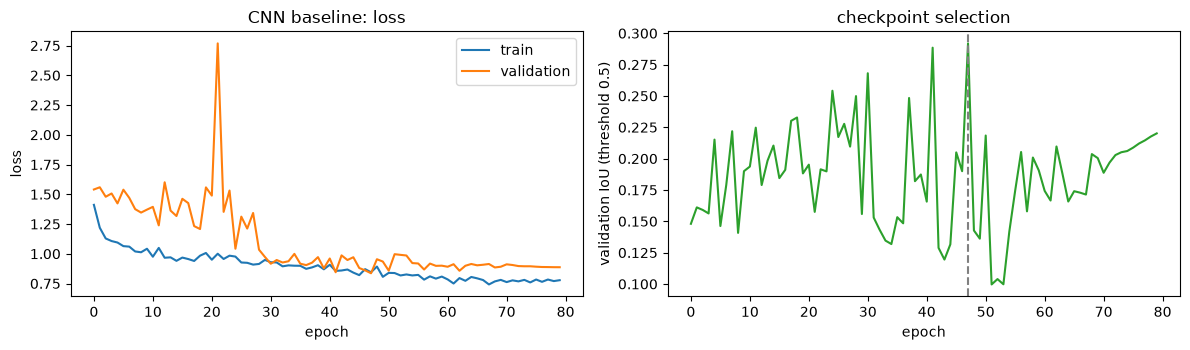

In [5]:
CNN_EPOCHS, CNN_BATCH = 80, 4
steps = int(np.ceil(len(x_train) / CNN_BATCH)) * CNN_EPOCHS
keras.utils.set_random_seed(SEED)
cnn, cnn_history = train("C_cnn", build_cnn_baseline((*IMG_SIZE, 3)), losses.bce_dice_loss,
                         keras.optimizers.AdamW(keras.optimizers.schedules.CosineDecay(1e-3, steps), weight_decay=1e-4),
                         CNN_EPOCHS, CNN_BATCH)
print(f"trainable parameters: {sum(int(np.prod(w.shape)) for w in cnn.trainable_weights):,}")
plot_history(cnn_history, "CNN baseline", "C_01_cnn_training.png")

In [6]:
cnn_result = calibrate(probabilities(cnn, x_val))
save("C_cnn", cnn, "CNN baseline (encoder-decoder, no skips)", cnn_result,
     {"author": "Hejer", "loss": "BCE + Dice", "optimizer": "AdamW 1e-3, wd 1e-4, cosine", "epochs": CNN_EPOCHS,
      "batch_size": CNN_BATCH, "best_epoch": int(np.argmax(cnn_history["val_iou"])) + 1})

saved models/C_cnn


# Part 2 — U-Net from scratch (Walid)

**Architecture** (`roadanomaly.models.unet.build_unet`):
- **Encoder:** four stages of two Conv-BN-ReLU blocks (16, 32, 64, 128 channels) with max pooling.
- **Bottleneck:** 256 channels.
- **Decoder:** ConvTranspose upsampling, then **concatenation with the encoder features of the same resolution** (skip connections), then two Conv-BN-ReLU blocks.
- **What the skips do:** they bring back the edges and small structures that the bottleneck loses. This is the difference FR asks Binôme C to measure (CNN vs U-Net).

**Recipe** (Walid): BCE + Dice, Adam with learning rate 1e-3, 50 epochs, batch 4, best validation IoU kept.

C_unet: 50 epochs | best epoch 43 | best val IoU 0.346


trainable parameters: 1,944,049


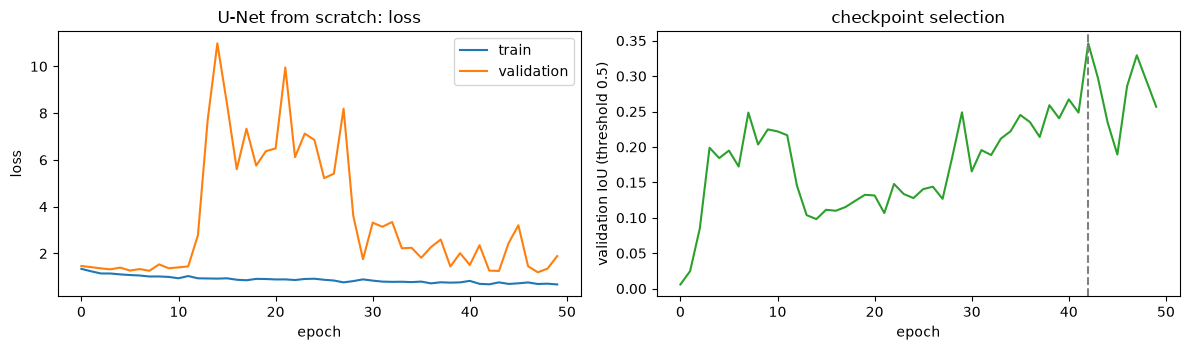

saved models/C_unet


In [7]:
UNET_EPOCHS, UNET_BATCH = 50, 4
unet, unet_history = train("C_unet", build_unet((*IMG_SIZE, 3)), losses.bce_dice_loss,
                           keras.optimizers.Adam(1e-3), UNET_EPOCHS, UNET_BATCH)
print(f"trainable parameters: {sum(int(np.prod(w.shape)) for w in unet.trainable_weights):,}")
plot_history(unet_history, "U-Net from scratch", "C_02_unet_training.png")
unet_result = calibrate(probabilities(unet, x_val))
save("C_unet", unet, "U-Net from scratch", unet_result,
     {"author": "Walid", "loss": "BCE + Dice", "optimizer": "Adam 1e-3", "epochs": UNET_EPOCHS,
      "batch_size": UNET_BATCH, "best_epoch": int(np.argmax(unet_history["val_iou"])) + 1})

# Part 3 — U-Net with a pretrained ImageNet encoder (Walid's improvement)

Walid's diagnosis was that 40 training images are too few to learn good features from scratch, so he used an encoder pretrained on ImageNet.

**Encoder.** `roadanomaly.models.unet.build_unet_resnet50`:
- A **ResNet50** is used instead of his ResNet34, which Keras does not provide.
- The skips come from its outputs at strides 2, 4, 8 and 16, and its stride-32 output is the bridge.
- The convolutions are fine-tuned. The BatchNorm statistics stay frozen, because batches of 8 are too small to re-estimate them.

**Recipe** (Walid):
- **Loss: focal + focal-Tversky** (α 0.3, β 0.7, γ 0.75). The focal term spends less effort on easy background pixels, and the Tversky term penalises missed anomaly pixels more than false alarms, to raise recall.
- **Optimiser:** AdamW with learning rate 3e-4 and weight decay 1e-4, cosine decay to 1e-6, and gradient clipping at 1.0.
- **Batch and stopping:** batch 8 (measured peak 4.6 GB at 352×640, within the 6 GB budget), at most 80 epochs, early stopping after 15 epochs without a better validation IoU.
- **Test-time augmentation:** the prediction is averaged with that of the mirrored image. It is kept only if it raises the validation AuPRC by more than `KEEP_MARGIN`.

The stronger augmentation of his notebook is replaced by the shared one (section 1). The threshold uses the shared rule, not his Dice-based grid.

C_unet_resnet50: 46 epochs | best epoch 31 | best val IoU 0.518


trainable parameters: 30,442,529


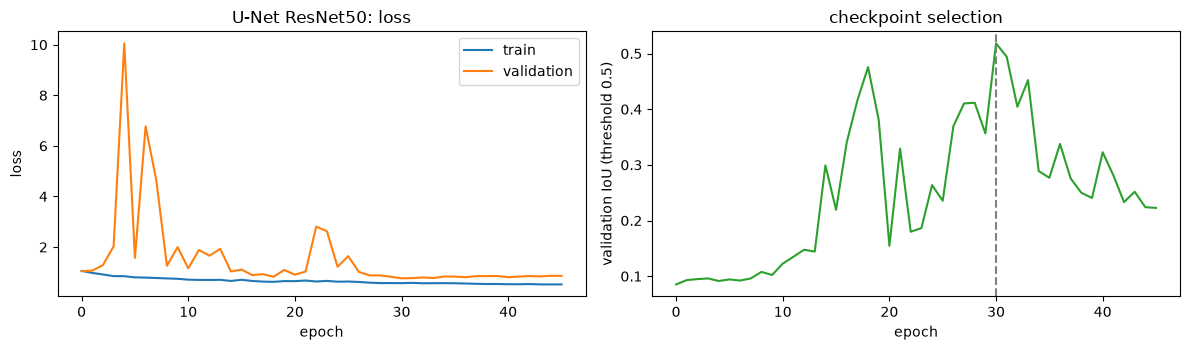

In [8]:
R50_EPOCHS, R50_BATCH, R50_PATIENCE = 80, 8, 15
steps = int(np.ceil(len(x_train) / R50_BATCH)) * R50_EPOCHS
schedule = keras.optimizers.schedules.CosineDecay(3e-4, steps, alpha=1e-6 / 3e-4)
keras.utils.set_random_seed(SEED)
unet_r50, r50_history = train("C_unet_resnet50", build_unet_resnet50((*IMG_SIZE, 3)), losses.focal_plus_tversky_loss,
                              keras.optimizers.AdamW(schedule, weight_decay=1e-4, clipnorm=1.0),
                              R50_EPOCHS, R50_BATCH, patience=R50_PATIENCE)
print(f"trainable parameters: {sum(int(np.prod(w.shape)) for w in unet_r50.trainable_weights):,}")
plot_history(r50_history, "U-Net ResNet50", "C_03_unet_resnet50_training.png")

In [9]:
# Flip test-time augmentation, kept only if it helps on validation
plain, with_tta = probabilities(unet_r50, x_val), probabilities(unet_r50, x_val, tta=True)
auprc_plain, auprc_tta = pp.auprc(gt_val, plain), pp.auprc(gt_val, with_tta)
USE_TTA = auprc_tta > auprc_plain + KEEP_MARGIN
print(f"validation AuPRC: without TTA {auprc_plain:.4f} | with flip-TTA {auprc_tta:.4f} -> TTA kept: {USE_TTA}")
r50_result = calibrate(with_tta if USE_TTA else plain)
save("C_unet_resnet50", unet_r50, "U-Net with ImageNet ResNet50 encoder", r50_result,
     {"author": "Walid (ResNet34 in the original, ResNet50 here)", "loss": "focal + focal-Tversky (0.3, 0.7, 0.75)",
      "optimizer": "AdamW 3e-4, wd 1e-4, cosine to 1e-6, clipnorm 1.0", "max_epochs": R50_EPOCHS,
      "epochs_ran": len(r50_history["loss"]), "patience": R50_PATIENCE, "batch_size": R50_BATCH,
      "best_epoch": int(np.argmax(r50_history["val_iou"])) + 1, "encoder": "ResNet50 ImageNet, BatchNorm frozen"},
     tta=bool(USE_TTA))

validation AuPRC: without TTA 0.7003 | with flip-TTA 0.7279 -> TTA kept: True


saved models/C_unet_resnet50


## 4. The three C models on validation
The shared report is used, with the same threshold rule for all three models. This table compares C's models with each other; A, B and C are compared on the test split in notebook 5.

In [10]:
results = {"CNN baseline (Hejer)": cnn_result, "U-Net from scratch (Walid)": unet_result,
           "U-Net ResNet50 (Walid)": r50_result}
table = pd.DataFrame({name: {**evaluation.summary(r["free"], r["report"]), "threshold": round(r["threshold"], 3)}
                      for name, r in results.items()})
table

,CNN baseline (Hejer),U-Net from scratch (Walid),U-Net ResNet50 (Walid)
AuPRC (main),0.41053,0.452569,0.727943
AUROC,0.905192,0.910704,0.914745
AUPRO@0.3,0.649404,0.707502,0.706482
FPR95 (lower is better),0.263867,0.360878,0.64515
F1 = Dice (per-image mean),0.502924,0.461488,0.642578
IoU (per-image mean),0.38194,0.364414,0.538199
precision (per-image mean),0.449695,0.409851,0.674884
recall (per-image mean),0.648364,0.582213,0.716533
F1 (aggregated),0.508552,0.558826,0.71045
Boundary IoU (15 px band),0.299457,0.268057,0.427988


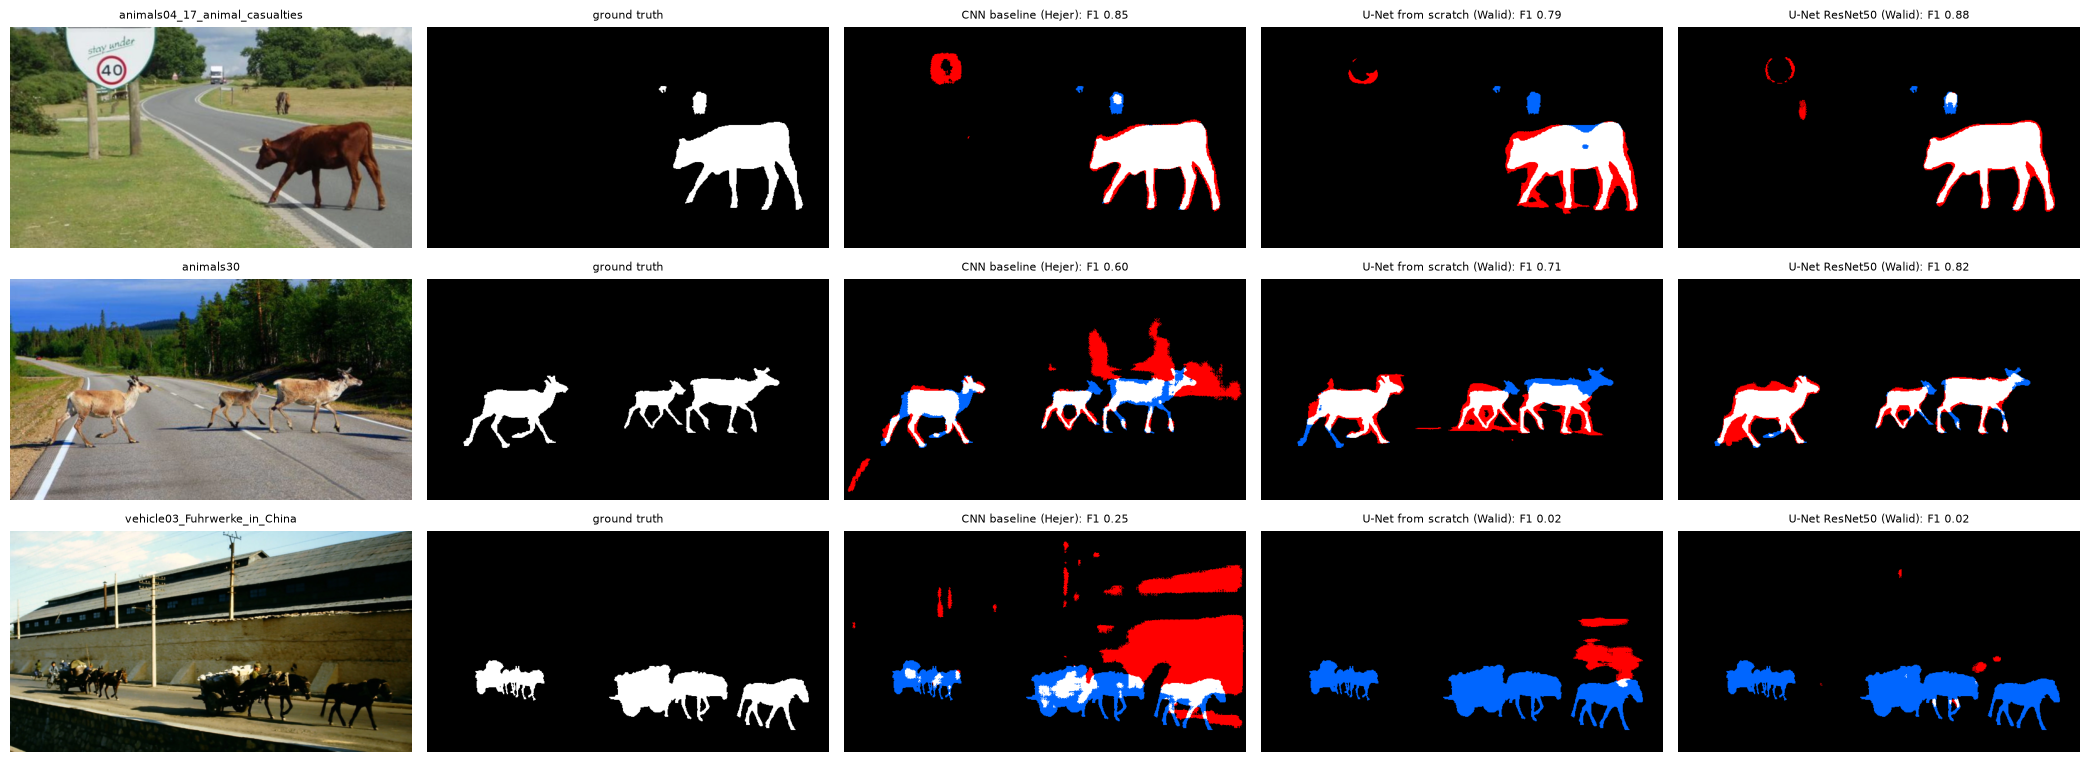

In [11]:
# Validation examples (first, middle, last): white = found, red = false alarm, blue = missed
def error_overlay(truth, pred):
    errors = np.zeros((*truth.shape, 3), np.float32)
    errors[truth & pred] = (1, 1, 1); errors[~truth & pred] = (1, 0, 0); errors[truth & ~pred] = (0, 0.4, 1)
    return errors

indices = [0, len(x_val) // 2, len(x_val) - 1]
fig, ax = plt.subplots(len(indices), 2 + len(results), figsize=(4.2 * (2 + len(results)), 2.6 * len(indices)), tight_layout=True)
for row, i in enumerate(indices):
    ax[row, 0].imshow(x_val[i]); ax[row, 0].set_title(val_frames[i][:30], fontsize=8)
    ax[row, 1].imshow(gt_val[i], cmap="gray"); ax[row, 1].set_title("ground truth", fontsize=8)
    for col, (name, r) in enumerate(results.items(), start=2):
        mask = pp.to_masks(r["prob"][i:i + 1], r["threshold"], r["min_blob"])[0].astype(bool)
        ax[row, col].imshow(error_overlay(gt_val[i], mask))
        ax[row, col].set_title(f"{name}: F1 {r['report']['pixel']['per_image'][i]['f1']:.2f}", fontsize=8)
for a in ax.flat:
    a.axis("off")
plt.savefig(FIG_DIR / "C_04_validation_examples.png", dpi=55)
plt.show()

## 5. Findings of the modeling phase (validation)
| Model (validation, shared protocol) | AuPRC | AUPRO@0.3 | F1 (per-image mean) | Objects found | Small objects | False alarms / blobs |
|---|---|---|---|---|---|---|
| CNN baseline (Hejer) | 0.411 | 0.649 | 0.503 | 27/36 | 7/12 | 132/199 |
| U-Net from scratch (Walid) | 0.453 | 0.708 | 0.461 | 26/36 | 9/12 | 33/47 |
| U-Net ResNet50 + flip-TTA (Walid) | **0.728** | 0.706 | **0.643** | 17/36 | 2/12 | 36/80 |

- **Skip connections help where they should.** The U-Net from scratch has a higher AuPRC and AUPRO than the CNN and four times fewer false-alarm blobs, and finds more small obstacles (9/12 vs 7/12): the encoder features of full resolution bring back the detail that pooling removes. Its per-image F1 on validation is lower, because its probabilities saturate (threshold 0.952); on the test split it is established as better than the CNN (notebook 5).
- **The pretrained encoder is decisive.** With an ImageNet ResNet50 encoder, the U-Net gains about 0.28 AuPRC; with 42 training photographs, learning features from scratch is the bottleneck, as Hejer's ResNet18 experiment already suggested. Flip test-time augmentation added 0.028 AuPRC on validation and was kept.
- **What the pretrained U-Net loses: small obstacles** (2/12 on validation). A likely reason, not tested here: its deep encoder stages see the image at 1/16 and 1/32 of its size, where a small obstacle is only a pixel or two.
- **Not comparable with the original runs.** Walid's ResNet34 U-Net reached a validation IoU of 0.815 on his own split; here the ResNet50 version reaches 0.518 at threshold 0.5. The difference most likely comes from the split (his was not group-aware, so frames of the same scene could be in both train and validation); the encoder also differs (ResNet34 is not in Keras), so the two runs cannot be compared directly.

The test evaluation of the three C models, next to A and B, is in [`../5_Evaluation.ipynb`](../5_Evaluation.ipynb); their paired explanations (Grad-CAM++ and exact SHAP) in [`../6_XAI.ipynb`](../6_XAI.ipynb).